# 1. 读取数据

In [14]:
import pandas as pd
import torch
from torch import nn, optim
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

df_train = pd.read_csv('../data/fashion-mnist_train.csv')
df_test = pd.read_csv('../data/fashion-mnist_test.csv')
print(df_train.columns[0])
print(df_train.columns[1])
print(df_train.shape)
print(df_test.shape)

# 2. 划分特征和标签，并转换为ndarray
# Purely integer-location based indexing for selection by position.
# iloc 是“我选我想要的”，drop 是“我丢我不想要的”
x_train = df_train.iloc[:, 1:].values #从第1 列开始
x_test = df_test.iloc[:, 1:].values
y_train = df_train.iloc[:, 0].values
y_test = df_test.iloc[:, 0].values


label
pixel1
(60000, 785)
(10000, 785)


In [15]:
# 3. 转换为张量，并调整形状为(N, C, H, W)
x_train = torch.tensor(x_train).reshape(-1, 1, 28, 28).float()
x_test = torch.tensor(x_test).reshape(-1, 1, 28, 28).float()
y_train = torch.tensor(y_train)
y_test = torch.tensor(y_test)


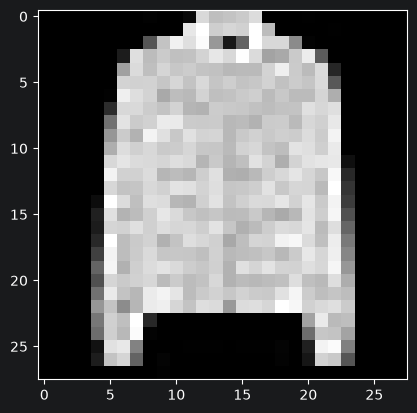

tensor(4)


In [16]:
# 显示图片
img = x_train[12345, 0]
plt.imshow(img, cmap='gray')
plt.show()
print(y_train[12345])

# 2. 定义训练超参数

In [17]:
lr = 0.01
epochs = 20
batch_size = 256

# 3. 创建数据加载器
train_dataset = TensorDataset(x_train, y_train)
val_dataset = TensorDataset(x_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)

In [18]:
# 4. 搭建模型
model = nn.Sequential(
    # shape=[N,6,28,28] 5 1 2  保持不变
    nn.Conv2d(1, 6, 5, 1, 2),
    nn.Sigmoid(),
    # shape=[N,6,14,14] 见一面砍一半
    nn.AvgPool2d(2, 2),

    #shape [N,16,10,10] 10=(H+2P-K)/S+1= (14-5)/1+1=9+1=10
    nn.Conv2d(6, 16, 5),
    nn.Sigmoid(),
    #shape [N,16,5,5]
    nn.AvgPool2d(2, 2),
    #SHAPE [N,400]
    nn.Flatten(),
    nn.Linear(16 * 5 * 5, 120),
    nn.Sigmoid(),
    nn.Linear(120, 84),
    nn.Sigmoid(),
    nn.Linear(84, 10),
)



In [19]:
# 5. 模型参数初始化
def init_weights(layer):
    if isinstance(layer, nn.Conv2d) or isinstance(layer, nn.Linear):
        nn.init.xavier_uniform_(layer.weight)
model.apply(init_weights)

# 6. 定义设备
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# 7. 定义损失函数和优化器
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)

# 8. 训练和验证
for epoch in range(epochs):
    # 训练
    model.train()
    train_loss = 0
    train_acc_num = 0

    # 遍历训练集，分批次迭代
    for input, target in train_loader:
        input, target = input.to(device), target.to(device)
        output = model(input)
        loss = loss_fn(output, target)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        # 累加损失及准确个数
        train_loss += loss.item()
        pred_label = output.argmax(dim=-1)
        train_acc_num += pred_label.eq(target).sum().item()
    # 训练完成，计算平均损失和准确率
    this_train_loss = train_loss / len(train_loader)
    this_train_acc = train_acc_num / len(train_dataset)

    # 验证
    model.eval()
    val_acc_num = 0

    # 遍历验证集，分批次迭代
    with torch.no_grad():
        for input, target in val_loader:
            input, target = input.to(device), target.to(device)
            output = model(input)

            # 累加准确个数
            pred_label = output.argmax(dim=-1)
            val_acc_num += pred_label.eq(target).sum().item()
    # 训练完成，计算平均损失和准确率
    this_val_acc = val_acc_num / len(val_dataset)

    print(f'Epoch: {epoch+1} train_loss: {this_train_loss:.6f} train_acc: {this_train_acc:.6f} val_acc: {this_val_acc:.6f}')



Epoch: 1 train_loss: 0.931843 train_acc: 0.650700 val_acc: 0.790600
Epoch: 2 train_loss: 0.487703 train_acc: 0.816467 val_acc: 0.823800
Epoch: 3 train_loss: 0.416321 train_acc: 0.845133 val_acc: 0.848000
Epoch: 4 train_loss: 0.377052 train_acc: 0.859483 val_acc: 0.865800
Epoch: 5 train_loss: 0.347984 train_acc: 0.870500 val_acc: 0.873100
Epoch: 6 train_loss: 0.331327 train_acc: 0.875567 val_acc: 0.871900
Epoch: 7 train_loss: 0.321334 train_acc: 0.878617 val_acc: 0.879500
Epoch: 8 train_loss: 0.308977 train_acc: 0.884050 val_acc: 0.884300
Epoch: 9 train_loss: 0.296432 train_acc: 0.889133 val_acc: 0.881900
Epoch: 10 train_loss: 0.286273 train_acc: 0.891833 val_acc: 0.887200
Epoch: 11 train_loss: 0.279384 train_acc: 0.894917 val_acc: 0.885000
Epoch: 12 train_loss: 0.270283 train_acc: 0.897200 val_acc: 0.887700
Epoch: 13 train_loss: 0.265750 train_acc: 0.899150 val_acc: 0.894200
Epoch: 14 train_loss: 0.258664 train_acc: 0.902500 val_acc: 0.898400
Epoch: 15 train_loss: 0.254551 train_acc: 0

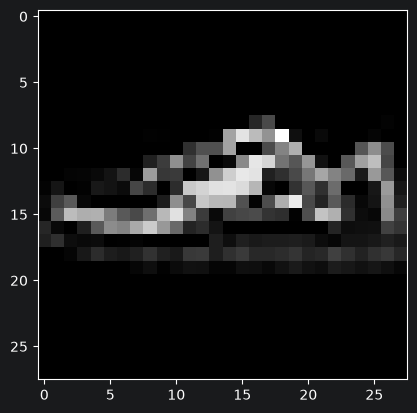

真实标签： tensor(7)


In [20]:
# 选取一张图片进行测试
img = x_test[666, 0]
plt.imshow(img, cmap='gray')
plt.show()
print("真实标签：", y_test[666])

In [23]:
print(img.shape)
x_new = img.unsqueeze(0).unsqueeze(0).to(device)
print(x_new.shape)
pred = model(x_new)
pred_label = pred.argmax(dim=-1)
print("预测标签：", pred_label)

torch.Size([28, 28])
torch.Size([1, 1, 28, 28])
预测标签： tensor([7])
